# Experiment 5: ANOVA and Non-Parametric Tests

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)
alpha = 0.05

## Load data

(333, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


,count,mean,std,median
species,,,,
Adelie,146,3706.16,458.62,3700.0
Chinstrap,68,3733.09,384.34,3700.0
Gentoo,119,5092.44,501.48,5050.0


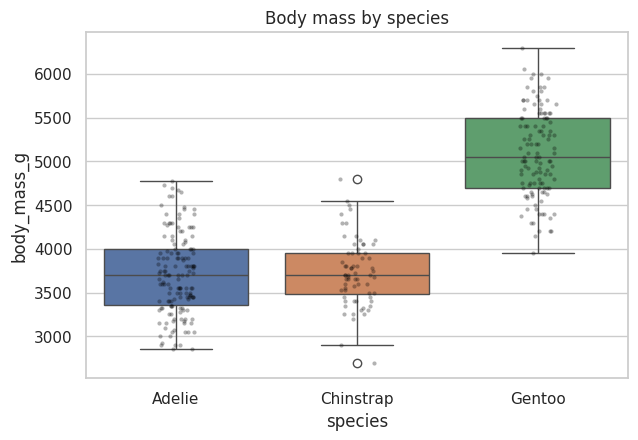

In [2]:
df = sns.load_dataset("penguins").dropna().reset_index(drop=True)
print(df.shape)
display(df.head())

display(df.groupby("species")["body_mass_g"].agg(["count", "mean", "std", "median"]).round(2))

plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="species", y="body_mass_g", hue="species", legend=False)
sns.stripplot(data=df, x="species", y="body_mass_g", color="black", alpha=0.3, size=3)
plt.title("Body mass by species")
plt.show()

## ANOVA assumptions

In [3]:
groups = {name: g["body_mass_g"].values for name, g in df.groupby("species")}
for name, vals in groups.items():
    W, p = stats.shapiro(vals)
    print(f"Shapiro-Wilk {name:10s}: W = {W:.4f}, p = {p:.4f}")

stat, p = stats.levene(*groups.values())
print(f"Levene test: statistic = {stat:.4f}, p = {p:.4f}")

Shapiro-Wilk Adelie    : W = 0.9812, p = 0.0423
Shapiro-Wilk Chinstrap : W = 0.9845, p = 0.5605
Shapiro-Wilk Gentoo    : W = 0.9861, p = 0.2605
Levene test: statistic = 5.1349, p = 0.0064


## One-way ANOVA

In [4]:
F, p = stats.f_oneway(*groups.values())
print(f"One-way ANOVA: F = {F:.4f}, p = {p:.3e}")

model = smf.ols("body_mass_g ~ C(species)", data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
display(anova_table)

ss_between = anova_table.loc["C(species)", "sum_sq"]
ss_total = anova_table["sum_sq"].sum()
print("Eta squared:", round(ss_between / ss_total, 4))

welch = anova_oneway(df["body_mass_g"], df["species"], use_var="unequal", welch_correction=True)
print("Welch ANOVA: F = %.4f, p = %.3e" % (welch.statistic, welch.pvalue))

One-way ANOVA: F = 341.8949, p = 3.745e-81


,sum_sq,df,F,PR(>F)
C(species),1.451902e+08,2.0,341.894895,3.744505e-81
Residual,7.006945e+07,330.0,NaN,NaN


Eta squared: 0.6745
Welch ANOVA: F = 316.5017, p = 7.441e-61


## Post-hoc test (Tukey HSD)

      Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1    group2   meandiff p-adj    lower     upper   reject
---------------------------------------------------------------
   Adelie Chinstrap   26.9239 0.9164 -132.3528  186.2005  False
   Adelie    Gentoo 1386.2726    0.0 1252.2897 1520.2554   True
Chinstrap    Gentoo 1359.3487    0.0 1194.4304 1524.2671   True
---------------------------------------------------------------


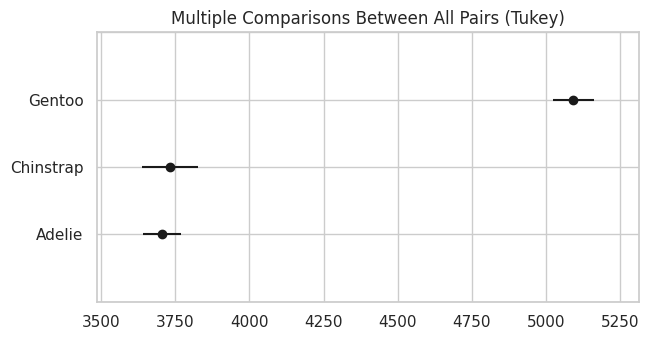

In [5]:
tukey = pairwise_tukeyhsd(endog=df["body_mass_g"], groups=df["species"], alpha=alpha)
print(tukey)

tukey.plot_simultaneous(figsize=(7, 3.5))
plt.show()

## Two-way ANOVA

,sum_sq,df,F,PR(>F)
C(species),1.434016e+08,2.0,749.015666,8.144406e-123
C(sex),3.709026e+07,1.0,387.459976,1.902273e-57
C(species):C(sex),1.676557e+06,2.0,8.756997,1.973489e-04
Residual,3.130263e+07,327.0,NaN,NaN


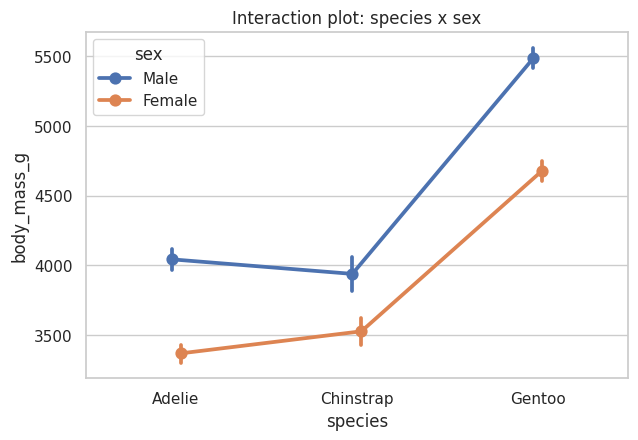

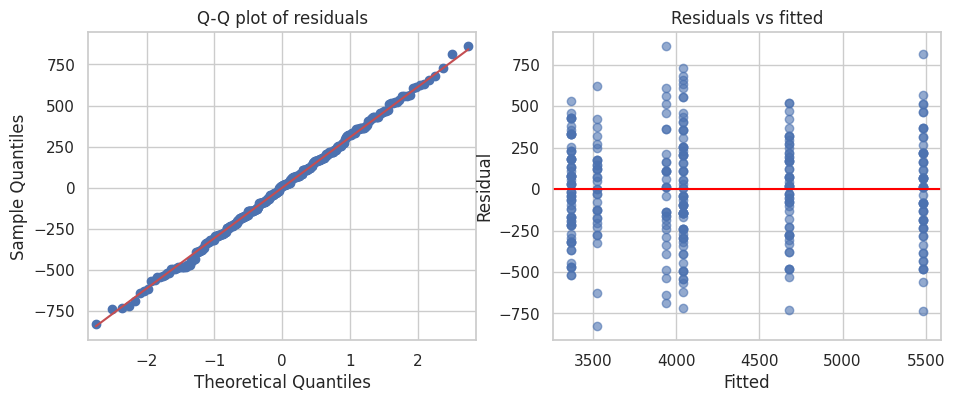

In [6]:
model2 = smf.ols("body_mass_g ~ C(species) * C(sex)", data=df).fit()
display(sm.stats.anova_lm(model2, typ=2))

plt.figure(figsize=(7, 4.5))
sns.pointplot(data=df, x="species", y="body_mass_g", hue="sex", dodge=True, errorbar="ci")
plt.title("Interaction plot: species x sex")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(model2.resid, line="s", ax=axes[0])
axes[0].set_title("Q-Q plot of residuals")
axes[1].scatter(model2.fittedvalues, model2.resid, alpha=0.6)
axes[1].axhline(0, color="red")
axes[1].set_xlabel("Fitted"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals vs fitted")
plt.show()

## Non-parametric: Kruskal-Wallis (alternative to one-way ANOVA)

In [7]:
H, p = stats.kruskal(*groups.values())
print(f"Kruskal-Wallis: H = {H:.4f}, p = {p:.3e}")

pairs = list(combinations(groups.keys(), 2))
rows = []
for a, b in pairs:
    U, p = stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided")
    rows.append([a, b, U, p, min(p * len(pairs), 1.0)])
posthoc = pd.DataFrame(rows, columns=["group_1", "group_2", "U", "p_raw", "p_bonferroni"])
posthoc["significant"] = posthoc["p_bonferroni"] < alpha
posthoc

Kruskal-Wallis: H = 212.0851, p = 8.837e-47


,group_1,group_2,U,p_raw,p_bonferroni,significant
0,Adelie,Chinstrap,4710.0,5.476168e-01,1.000000e+00,False
1,Adelie,Gentoo,358.5,4.519357e-41,1.355807e-40,True
2,Chinstrap,Gentoo,119.0,2.746723e-28,8.240168e-28,True


## Non-parametric: Mann-Whitney U (two independent groups)

In [8]:
gentoo = df[df["species"] == "Gentoo"]
male = gentoo.loc[gentoo["sex"] == "Male", "flipper_length_mm"]
female = gentoo.loc[gentoo["sex"] == "Female", "flipper_length_mm"]
U, p = stats.mannwhitneyu(male, female, alternative="two-sided")
print(f"Mann-Whitney U = {U:.2f}, p = {p:.3e}")

Mann-Whitney U = 3173.50, p = 7.620e-14


## Non-parametric: Wilcoxon signed-rank (paired samples)

In [9]:
before = rng.normal(70, 10, 25)
after = before - rng.exponential(scale=3, size=25)
W, p = stats.wilcoxon(before, after)
print(f"Wilcoxon signed-rank: W = {W:.2f}, p = {p:.5f}")
print("Paired t-test for comparison:", stats.ttest_rel(before, after))

Wilcoxon signed-rank: W = 0.00, p = 0.00000
Paired t-test for comparison: TtestResult(statistic=np.float64(7.109428410368416), pvalue=np.float64(2.38585750885635e-07), df=np.int64(24))


## Non-parametric: Friedman test (repeated measures)

In [10]:
subjects = 20
t1 = rng.normal(50, 5, subjects)
t2 = t1 + rng.normal(2, 2, subjects)
t3 = t1 + rng.normal(4, 2, subjects)
chi, p = stats.friedmanchisquare(t1, t2, t3)
print(f"Friedman: chi2 = {chi:.4f}, p = {p:.5f}")

Friedman: chi2 = 28.9000, p = 0.00000


## Non-parametric: Kolmogorov-Smirnov and Mood's median tests

In [11]:
ks, p = stats.ks_2samp(groups["Adelie"], groups["Gentoo"])
print(f"Two-sample KS (Adelie vs Gentoo): D = {ks:.4f}, p = {p:.3e}")

stat, p, med, table = stats.median_test(*groups.values())
print(f"Mood's median test: chi2 = {stat:.4f}, p = {p:.3e}, grand median = {med}")

Two-sample KS (Adelie vs Gentoo): D = 0.8384, p = 1.600e-47
Mood's median test: chi2 = 192.0523, p = 1.979e-42, grand median = 4050.0


## ANOVA vs Kruskal-Wallis on non-normal data

In [12]:
g1 = rng.exponential(1.0, 30)
g2 = rng.exponential(1.5, 30)
g3 = rng.exponential(3.0, 30)
print("Shapiro p-values:", [round(stats.shapiro(g)[1], 4) for g in (g1, g2, g3)])
print("ANOVA:", stats.f_oneway(g1, g2, g3))
print("Kruskal-Wallis:", stats.kruskal(g1, g2, g3))

pd.DataFrame({
    "test": ["One-way ANOVA", "Welch ANOVA", "Kruskal-Wallis"],
    "p_value": [stats.f_oneway(*groups.values())[1], welch.pvalue, stats.kruskal(*groups.values())[1]],
}).assign(decision=lambda d: np.where(d["p_value"] < alpha, "Reject H0", "Fail to reject H0"))

Shapiro p-values: [np.float64(0.0), np.float64(0.0002), np.float64(0.005)]
ANOVA: F_onewayResult(statistic=np.float64(12.890411657000499), pvalue=np.float64(1.2498377843851379e-05))
Kruskal-Wallis: KruskalResult(statistic=np.float64(19.590329670329652), pvalue=np.float64(5.5720366298234625e-05))


,test,p_value,decision
0,One-way ANOVA,3.744505e-81,Reject H0
1,Welch ANOVA,7.441166e-61,Reject H0
2,Kruskal-Wallis,8.836877e-47,Reject H0
